In [1]:
import pandas as pd

df = pd.read_csv("SMQ_STATUS.csv")

print(df.shape[0])

9015


In [2]:
import pandas as pd

df = pd.read_csv("SMQ_STATUS.csv")

# Keep rows where the second column is NOT 7 or 9
df = df[~df.iloc[:, 1].isin([7, 9])]

# Save to a new CSV
df.to_csv("SMQ_STATUS_AVAILABLE.csv", index=False)

In [6]:
import pandas as pd

df = pd.read_csv("SMQ_STATUS_AVAILABLE.csv")

print(df.shape[0])

8121


In [5]:
import pandas as pd

df = pd.read_csv("SMQ_STATUS.csv")

# Remove rows with 7, 9, or NaN in the second column
df = df[~df.iloc[:, 1].isin([7, 9])]
df = df.dropna(subset=[df.columns[1]])

# Save to a new CSV
df.to_csv("SMQ_STATUS_AVAILABLE.csv", index=False)

In [7]:
import pandas as pd

df = pd.read_csv("PAQ_MET.csv")

print(df.shape[0])

8121


In [12]:

import pandas as pd
from pathlib import Path

# Folder containing all CSV files


# Read classification files
paq = pd.read_csv("PAQ_MET.csv")
smq = pd.read_csv("SMQ_STATUS_AVAILABLE.csv")

# Response files
response_files = [
    "BMI.csv",
    "Systolic_BP.csv",
    "Glycohemoglobin.csv",
    "Diastolic_BP.csv",
    "HDL.csv",
    "Total_Cholesterol.csv",
    "Triglycerides.csv",
    "Fasting_Glucose.csv"
]

# Merge classifications into every response file
for filename in response_files:

    response = pd.read_csv(filename)

    merged = response.merge(
        paq,
        on="SEQN",
        how="left",
        validate="one_to_one"
    )

    merged = merged.merge(
        smq,
        on="SEQN",
        how="left",
        validate="one_to_one"
    )

    # Save final response file
    output_name = filename.replace(".csv", "_FINAL.csv")

    merged.to_csv(
        output_name,
        index=False
    )

    print(f"{output_name} saved:", merged.shape)


BMI_FINAL.csv saved: (11933, 24)
Systolic_BP_FINAL.csv saved: (11933, 24)
Glycohemoglobin_FINAL.csv saved: (11933, 24)
Diastolic_BP_FINAL.csv saved: (11933, 24)
HDL_FINAL.csv saved: (11933, 24)
Total_Cholesterol_FINAL.csv saved: (11933, 24)
Triglycerides_FINAL.csv saved: (11933, 24)
Fasting_Glucose_FINAL.csv saved: (11933, 24)


In [14]:
import pandas as pd
from pathlib import Path



response_files = [
    "BMI_FINAL.csv",
    "Systolic_BP_FINAL.csv",
    "Glycohemoglobin_FINAL.csv",
    "Diastolic_BP_FINAL.csv",
    "HDL_FINAL.csv",
    "Total_Cholesterol_FINAL.csv",
    "Triglycerides_FINAL.csv",
    "Fasting_Glucose_FINAL.csv"
]

for filename in response_files:

    df = pd.read_csv(filename)

    # Remove rows with NaN in the fifth column
    fifth_column = df.columns[4]

    df = df.dropna(subset=[fifth_column])

    df.to_csv(filename, index=False)

    print(filename, "->", df.shape)

BMI_FINAL.csv -> (8471, 24)
Systolic_BP_FINAL.csv -> (7518, 24)
Glycohemoglobin_FINAL.csv -> (6715, 24)
Diastolic_BP_FINAL.csv -> (7518, 24)
HDL_FINAL.csv -> (6890, 24)
Total_Cholesterol_FINAL.csv -> (6890, 24)
Triglycerides_FINAL.csv -> (3517, 24)
Fasting_Glucose_FINAL.csv -> (3672, 24)


In [3]:
import pandas as pd

# Read files
sys = pd.read_csv("Systolic_BP_FINAL.csv")
dia = pd.read_csv("Diastolic_BP_FINAL.csv")
bp_avg = pd.read_csv("BP_AVG.csv")

# Match SEQN and replace systolic values
sys = sys.drop(columns=["SYS_AVG"], errors="ignore")
sys = sys.merge(
    bp_avg[["SEQN", "SYS_AVG"]],
    on="SEQN",
    how="inner"
)

# Match SEQN and replace diastolic values
dia = dia.drop(columns=["DIA_AVG"], errors="ignore")
dia = dia.merge(
    bp_avg[["SEQN", "DIA_AVG"]],
    on="SEQN",
    how="inner"
)

# Save corrected files
sys.to_csv("Systolic_Corrected.csv", index=False)
dia.to_csv("Diastolic_Corrected.csv", index=False)
print("Systolic_Corrected.csv ->", sys.shape)
print("Diastolic_Corrected.csv ->", dia.shape)

Systolic_Corrected.csv -> (7478, 24)
Diastolic_Corrected.csv -> (7478, 24)


In [1]:
import pandas as pd

# Read file
BMI = pd.read_csv("BMI_FINAL.csv")

# Valid sample: participants with valid Physical Activity and BMI
valid_sample = BMI[
    BMI["MET_Level"].notna() &
    BMI["BMXBMI"].notna()
]

N_valid = len(valid_sample)

# Event A: Inactive and Normal Weight
event = valid_sample[
    (valid_sample["MET_Level"] == 0) &
    (valid_sample["BMXBMI"] >= 18.5) &
    (valid_sample["BMXBMI"] <= 24.9)
]

n_event = len(event)

# Empirical probability
P_A = n_event / N_valid

print("Valid sample:", N_valid)
print("Number of participants in Event A:", n_event)
print("Empirical probability:", P_A)


Valid sample: 6219
Number of participants in Event A: 225
Empirical probability: 0.0361794500723589


In [2]:

import pandas as pd

# Read files
HbA1c = pd.read_csv("Glycohemoglobin_FINAL.csv")
Glucose = pd.read_csv("Fasting_Glucose_FINAL.csv")

# Merge by participant ID
merged = HbA1c[["SEQN", "MET_Level", "LBXGH"]].merge(
    Glucose[["SEQN", "LBXGLU"]],
    on="SEQN",
    how="inner"
)

# Valid sample: valid observations for all three variables
valid_sample = merged.dropna(
    subset=["MET_Level", "LBXGH", "LBXGLU"]
)

N_valid = len(valid_sample)

# Event C: Inactive + Normal Glycohemoglobin + Normal Fasting Glucose
event_C = valid_sample[
    (valid_sample["MET_Level"] == 0) &
    (valid_sample["LBXGH"] < 5.7) &
    (valid_sample["LBXGLU"] < 100)
]

n_event_C = len(event_C)

# Empirical probability
P_C = n_event_C / N_valid

print("Valid sample:", N_valid)
print("Participants satisfying Event C:", n_event_C)
print("Empirical probability of Event C:", P_C)


Valid sample: 3321
Participants satisfying Event C: 175
Empirical probability of Event C: 0.05269497139415839


In [3]:
import pandas as pd

# Read files
SYS = pd.read_csv("Systolic_BP_FINAL.csv")
DIA = pd.read_csv("Diastolic_Corrected_FINAL.csv")

# Merge systolic and diastolic BP
merged = SYS[["SEQN", "SYS_AVG", "Smoking_Level"]].merge(
    DIA[["SEQN", "DIA_AVG"]],
    on="SEQN",
    how="inner"
)

# Valid sample
valid_sample = merged.dropna(
    subset=["SYS_AVG", "DIA_AVG", "Smoking_Level"]
)

N_valid = len(valid_sample)

# Event B': Current Smoker + Normal Systolic and Diastolic BP
event_B_prime = valid_sample[
    (valid_sample["Smoking_Level"] == 2) &
    (valid_sample["SYS_AVG"] < 120) &
    (valid_sample["DIA_AVG"] < 80)
]

n_event_B_prime = len(event_B_prime)

# Empirical probability
P_B_prime = n_event_B_prime / N_valid

print("Valid sample:", N_valid)
print("Participants satisfying Event B':", n_event_B_prime)
print("Empirical probability of Event B':", P_B_prime)


Valid sample: 6091
Participants satisfying Event B': 361
Empirical probability of Event B': 0.05926777212280414


In [4]:

import pandas as pd

# Read files
HDL = pd.read_csv("HDL_FINAL.csv")
TC = pd.read_csv("Total_Cholesterol_FINAL.csv")
TG = pd.read_csv("Triglycerides_FINAL.csv")

# Merge lipid measurements
merged = HDL[["SEQN", "LBDHDD", "Smoking_Level"]].merge(
    TC[["SEQN", "LBXTC"]],
    on="SEQN",
    how="inner",
    validate="one_to_one"
).merge(
    TG[["SEQN", "LBXTLG"]],
    on="SEQN",
    how="inner",
    validate="one_to_one"
)

# Valid sample
valid_sample = merged.dropna(
    subset=["LBDHDD", "LBXTC", "LBXTLG", "Smoking_Level"]
)

N_valid = len(valid_sample)

# Event D': Current Smoker + Normal Lipid Profile
event_D_prime = valid_sample[
    (valid_sample["Smoking_Level"] == 2) &
    (valid_sample["LBDHDD"] >= 40) &
    (valid_sample["LBXTC"] < 200) &
    (valid_sample["LBXTLG"] < 150)
]

n_event_D_prime = len(event_D_prime)

# Empirical probability
P_D_prime = n_event_D_prime / N_valid

print("Valid sample:", N_valid)
print("Participants satisfying Event D':", n_event_D_prime)
print("Empirical probability of Event D':", P_D_prime)


Valid sample: 3184
Participants satisfying Event D': 167
Empirical probability of Event D': 0.05244974874371859


In [6]:

import pandas as pd

BMI = pd.read_csv("BMI_FINAL.csv")
HbA1c = pd.read_csv("Glycohemoglobin_FINAL.csv")
Glucose = pd.read_csv("Fasting_Glucose_FINAL.csv")

merged = BMI[["SEQN", "MET_Level", "BMXBMI"]].merge(
    HbA1c[["SEQN", "LBXGH"]],
    on="SEQN",
    how="inner"
).merge(
    Glucose[["SEQN", "LBXGLU"]],
    on="SEQN",
    how="inner"
)

# Participants with valid observations
valid_sample = merged.dropna(
    subset=["MET_Level", "BMXBMI", "LBXGH", "LBXGLU"]
)

N_valid = len(valid_sample)

# Participants satisfying A and C simultaneously
event_AC = valid_sample[
    (valid_sample["MET_Level"] == 0) &
    (valid_sample["BMXBMI"].between(18.5, 24.9)) &
    (valid_sample["LBXGH"] < 5.7) &
    (valid_sample["LBXGLU"] < 100)
]

n_AC = len(event_AC)

P_AC = n_AC / N_valid

print("Valid sample:", N_valid)
print("Participants in A ∩ C:", n_AC)
print("Joint probability:", P_AC)
print("Joint probability (%):", P_AC * 100)


Valid sample: 3278
Participants in A ∩ C: 53
Joint probability: 0.016168395363026236
Joint probability (%): 1.6168395363026236


In [8]:

import pandas as pd

SYS = pd.read_csv("Systolic_BP_FINAL.csv")
DIA = pd.read_csv("Diastolic_Corrected_FINAL.csv")
HDL = pd.read_csv("HDL_FINAL.csv")
TC = pd.read_csv("Total_Cholesterol_FINAL.csv")
TG = pd.read_csv("Triglycerides_FINAL.csv")

# Merge all datasets using SEQN
merged = SYS[["SEQN", "SYS_AVG", "Smoking_Level"]].merge(
    DIA[["SEQN", "DIA_AVG"]],
    on="SEQN",
    how="inner"
).merge(
    HDL[["SEQN", "LBDHDD"]],
    on="SEQN",
    how="inner"
).merge(
    TC[["SEQN", "LBXTC"]],
    on="SEQN",
    how="inner"
).merge(
    TG[["SEQN", "LBXTLG"]],
    on="SEQN",
    how="inner"
)

# Participants with valid observations
valid_sample = merged.dropna(
    subset=[
        "SYS_AVG", "DIA_AVG", "LBDHDD",
        "LBXTC", "LBXTLG", "Smoking_Level"
    ]
)

N_valid = len(valid_sample)

# Participants satisfying B' and D' simultaneously
event_BD = valid_sample[
    (valid_sample["Smoking_Level"] == 2) &
    (valid_sample["SYS_AVG"] < 120) &
    (valid_sample["DIA_AVG"] < 80) &
    (valid_sample["LBDHDD"] >= 40) &
    (valid_sample["LBXTC"] < 200) &
    (valid_sample["LBXTLG"] < 150)
]

n_BD = len(event_BD)

P_BD = n_BD / N_valid

print("Valid sample:", N_valid)
print("Participants in B' ∩ D':", n_BD)
print("Joint probability:", P_BD)
print("Joint probability (%):", P_BD * 100)


Valid sample: 3060
Participants in B' ∩ D': 69
Joint probability: 0.022549019607843137
Joint probability (%): 2.2549019607843137


In [2]:
import pandas as pd

df = pd.read_csv("BMI_FINAL.csv")

# Count males and females by numerical physical activity level
gender_counts = pd.crosstab(
    df["MET_Level"],
    df["RIAGENDR"]
)

# Translate numerical codes into descriptive labels
gender_counts = gender_counts.rename(
    index={
        0: "Inactive",
        1: "Low",
        2: "Active",
        3: "Highly Active"
    },
    columns={
        1: "Male",
        2: "Female"
    }
)

# Ensure all four groups are included
gender_counts = gender_counts.reindex(
    ["Inactive", "Low", "Active", "Highly Active"],
    fill_value=0
)

# Add row totals
gender_counts["Total"] = gender_counts["Male"] + gender_counts["Female"]

print(gender_counts)

RIAGENDR       Male  Female  Total
MET_Level                         
Inactive        473     710   1183
Low             670    1074   1744
Active          703     840   1543
Highly Active   959     790   1749


In [3]:
# Calculate conditional probabilities using existing counts
conditional_prob = gender_counts[["Male", "Female"]].div(
    gender_counts[["Male", "Female"]].sum(axis=0),
    axis=1
)

print("Conditional probabilities:")
print(conditional_prob)

Conditional probabilities:
RIAGENDR           Male    Female
MET_Level                        
Inactive       0.168627  0.207967
Low            0.238859  0.314587
Active         0.250624  0.246046
Highly Active  0.341889  0.231400


In [4]:
print("Sum of conditional probabilities:")
print(conditional_prob.sum(axis=0))

Sum of conditional probabilities:
RIAGENDR
Male      1.0
Female    1.0
dtype: float64


In [1]:
import pandas as pd

df = pd.read_csv("BMI_FINAL.csv")

# Classify BMI into five categories
df["BMI_Category"] = pd.cut(
    df["BMXBMI"],
    bins=[-float("inf"), 18.5, 25, 30, 40, float("inf")],
    labels=[
        "Underweight",
        "Normal Weight",
        "Overweight",
        "Obese",
        "Severely Obese"
    ],
    right=False
)

# Count participants in each BMI category by MET level
bmi_counts = pd.crosstab(
    df["MET_Level"],
    df["BMI_Category"]
)

# Ensure all groups are included
bmi_counts = bmi_counts.reindex(
    index=[0, 1, 2, 3],
    columns=[
        "Underweight",
        "Normal Weight",
        "Overweight",
        "Obese",
        "Severely Obese"
    ],
    fill_value=0
)

# Add row totals
bmi_counts["Total"] = bmi_counts.sum(axis=1)

print("Frequency distribution:")
print(bmi_counts)

# Calculate conditional probabilities
conditional_prob_bmi = bmi_counts.drop(
    columns="Total"
).div(
    bmi_counts["Total"],
    axis=0
)

print("\nConditional probabilities:")
print(conditional_prob_bmi)

# Check that probabilities sum to 1 for each MET group
print("\nProbability sum check:")
print(conditional_prob_bmi.sum(axis=1))

Frequency distribution:
BMI_Category  Underweight  Normal Weight  Overweight  Obese  Severely Obese  \
MET_Level                                                                     
0                      17            225         326    424             191   
1                      32            375         532    606             199   
2                      31            440         532    437             103   
3                      28            596         566    470              89   

BMI_Category  Total  
MET_Level            
0              1183  
1              1744  
2              1543  
3              1749  

Conditional probabilities:
BMI_Category  Underweight  Normal Weight  Overweight     Obese  Severely Obese
MET_Level                                                                     
0                0.014370       0.190194    0.275571  0.358411        0.161454
1                0.018349       0.215023    0.305046  0.347477        0.114106
2                0.020091

In [2]:
import pandas as pd

df = pd.read_csv("BMI_FINAL.csv")

# Exclude missing values
df = df.dropna(subset=["INDFMPIR", "Smoking_Level"])

# Classify family income
df["Income_Group"] = df["INDFMPIR"].apply(
    lambda x: "Low Income" if x < 1 else "Higher Income"
)

# Count smoking status within each income group
smoking_counts = pd.crosstab(
    df["Income_Group"],
    df["Smoking_Level"]
)

# Ensure all smoking categories are included
smoking_counts = smoking_counts.reindex(
    index=["Low Income", "Higher Income"],
    columns=[0, 1, 2],
    fill_value=0
)

# Translate numerical codes
smoking_counts = smoking_counts.rename(
    columns={
        0: "Never",
        1: "Former",
        2: "Current"
    }
)

# Add row totals
smoking_counts["Total"] = smoking_counts.sum(axis=1)

print("Frequency distribution:")
print(smoking_counts)

# Calculate conditional probabilities
conditional_prob_smoking = smoking_counts.drop(
    columns="Total"
).div(
    smoking_counts["Total"],
    axis=0
)

print("\nConditional probabilities:")
print(conditional_prob_smoking)

# Check that each income group's probabilities sum to 1
print("\nProbability sum check:")
print(conditional_prob_smoking.sum(axis=1))

Frequency distribution:
Smoking_Level  Never  Former  Current  Total
Income_Group                                
Low Income       451     170      244    865
Higher Income   2766    1220      563   4549

Conditional probabilities:
Smoking_Level     Never    Former   Current
Income_Group                               
Low Income     0.521387  0.196532  0.282081
Higher Income  0.608046  0.268191  0.123763

Probability sum check:
Income_Group
Low Income       1.0
Higher Income    1.0
dtype: float64


In [3]:

import pandas as pd

# ==========================================
# 1. Read CSV files
# ==========================================

hdl = pd.read_csv("HDL_FINAL.csv")
tc = pd.read_csv("Total_Cholesterol_FINAL.csv")
tg = pd.read_csv("Triglycerides_FINAL.csv")


# ==========================================
# 2. Define column names
# ==========================================

ID = "SEQN"

HDL_COL = "LBDHDD"
TC_COL = "LBXTC"
TG_COL = "LBXTLG"

SEX_COL = "RIAGENDR"

# Your smoking group column
SMOKING_COL = "Smoking_Level"


# ==========================================
# 3. Select required columns
# ==========================================

hdl = hdl[[ID, HDL_COL, SEX_COL, SMOKING_COL]]
tc = tc[[ID, TC_COL]]
tg = tg[[ID, TG_COL]]


# ==========================================
# 4. Merge three datasets
# ==========================================

df = pd.merge(hdl, tc, on=ID, how="inner")
df = pd.merge(df, tg, on=ID, how="inner")


# ==========================================
# 5. Remove missing values
# ==========================================

df = df.dropna(
    subset=[HDL_COL, TC_COL, TG_COL, SEX_COL, SMOKING_COL]
).copy()


# ==========================================
# 6. Classify HDL
# ==========================================

df["HDL_Group"] = "Unclassified"

# Low HDL
df.loc[
    ((df[SEX_COL] == 1) & (df[HDL_COL] < 40)) |
    ((df[SEX_COL] == 2) & (df[HDL_COL] < 50)),
    "HDL_Group"
] = "Low"

# Normal HDL
df.loc[
    ((df[SEX_COL] == 1) & (df[HDL_COL] >= 40) & (df[HDL_COL] <= 80)) |
    ((df[SEX_COL] == 2) & (df[HDL_COL] >= 50) & (df[HDL_COL] <= 80)),
    "HDL_Group"
] = "Normal"


# ==========================================
# 7. Classify Total Cholesterol
# ==========================================

df["TC_Group"] = "Normal"

df.loc[df[TC_COL] >= 200, "TC_Group"] = "High"


# ==========================================
# 8. Classify Triglycerides
# ==========================================

df["TG_Group"] = "Normal"

df.loc[df[TG_COL] >= 150, "TG_Group"] = "Elevated"


# ==========================================
# 9. Remove unclassified HDL
# ==========================================

df = df[df["HDL_Group"] != "Unclassified"].copy()


# ==========================================
# 10. Create 8 lipid profile groups
# ==========================================

df["Lipid_Profile"] = (
    df["HDL_Group"] + " HDL | " +
    df["TC_Group"] + " TC | " +
    df["TG_Group"] + " TG"
)


# ==========================================
# 11. Name smoking groups
# ==========================================

smoking_names = {
    0: "Never",
    1: "Former",
    2: "Current"
}

df["Smoking_Status"] = df[SMOKING_COL].map(smoking_names)

df = df.dropna(subset=["Smoking_Status"])


# ==========================================
# 12. Frequency table
# ==========================================

counts = pd.crosstab(
    df["Lipid_Profile"],
    df["Smoking_Status"]
)

all_profiles = [
    f"{h} HDL | {t} TC | {g} TG"
    for h in ["Low", "Normal"]
    for t in ["Normal", "High"]
    for g in ["Normal", "Elevated"]
]

counts = counts.reindex(
    index=all_profiles,
    columns=["Never", "Former", "Current"],
    fill_value=0
)

counts["Total"] = counts.sum(axis=1)

print("\nFREQUENCY TABLE")
print(counts)


# ==========================================
# 13. Conditional probability table
# ==========================================

probabilities = counts[["Never", "Former", "Current"]].div(
    counts[["Never", "Former", "Current"]].sum(axis=0),
    axis=1
)



print("\nCONDITIONAL PROBABILITY ")
print(probabilities.round(6))


# ==========================================
# 14. Save results
# ==========================================

counts.to_csv("Lipid_Profile_Frequency.csv")

probabilities.to_csv("Lipid_Profile_Conditional_Probability.csv")

print("\nBoth tables saved successfully!")



FREQUENCY TABLE
Smoking_Status                        Never  Former  Current  Total
Lipid_Profile                                                      
Low HDL | Normal TC | Normal TG         232      85       49    366
Low HDL | Normal TC | Elevated TG        95      66       29    190
Low HDL | High TC | Normal TG            50       9       10     69
Low HDL | High TC | Elevated TG          76      37       30    143
Normal HDL | Normal TC | Normal TG      803     330      139   1272
Normal HDL | Normal TC | Elevated TG     89      48       17    154
Normal HDL | High TC | Normal TG        410     136       70    616
Normal HDL | High TC | Elevated TG      104      64       31    199

CONDITIONAL PROBABILITY 
Smoking_Status                           Never    Former   Current
Lipid_Profile                                                     
Low HDL | Normal TC | Normal TG       0.124798  0.109677  0.130667
Low HDL | Normal TC | Elevated TG     0.051103  0.085161  0.077333
Low HDL |

Total participants: 3517
Elevated participants: 711
Estimated p (MLE): 0.20216093261302245


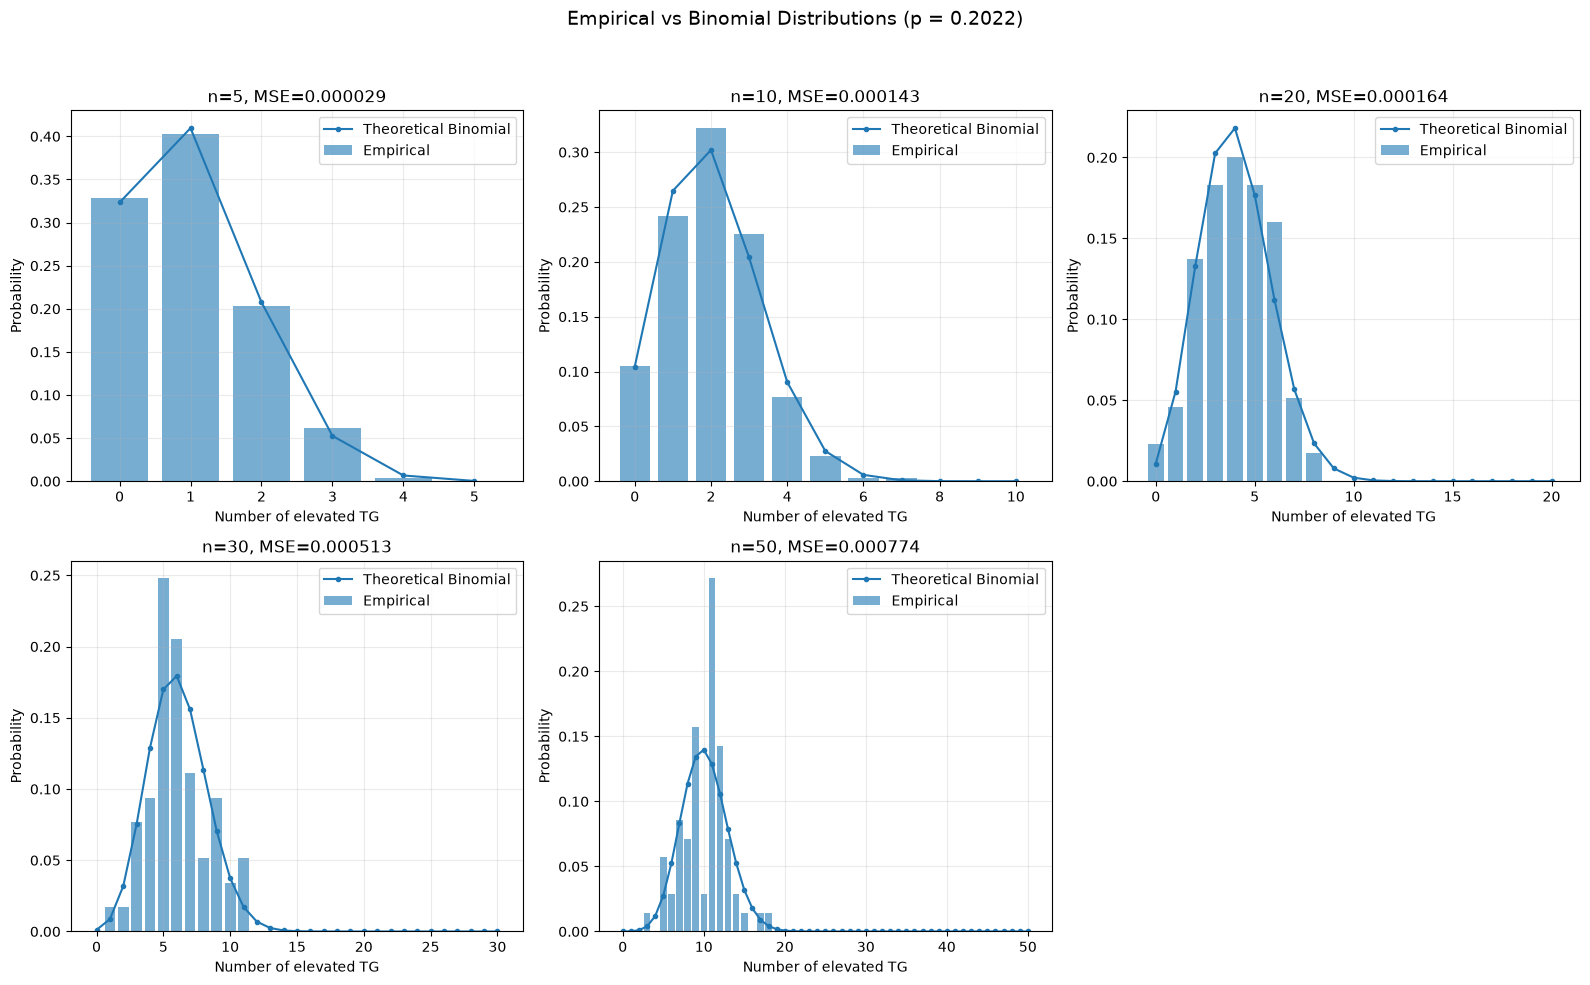


Comparison of different group sizes:

 Group Size (n)  Number of Groups      MSE  Theoretical Mean  Empirical Mean  Theoretical Variance  Empirical Variance
              5               703 0.000070          1.010805        1.009957              0.806459            0.824687
             10               351 0.000163          2.021609        2.022792              1.612919            1.530908
             20               175 0.000193          4.043219        4.034286              3.225838            3.757438
             30               117 0.000149          6.064828        6.051282              4.838757            4.376658
             50                70 0.000190         10.108047       10.114286              8.064594            8.044720


In [8]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binom

# ---------------------------------
# 1. Load and prepare the data
# ---------------------------------

df = pd.read_csv("Triglycerides_FINAL.csv")

TG_COL = "LBXTLG"

tg = df[TG_COL].dropna()

# Binary classification:
# 1 = Elevated TG (>=150)
# 0 = Normal TG (<150)

binary_original = (tg >= 150).astype(int).to_numpy()

# ---------------------------------
# 2. MLE estimation of p
# ---------------------------------

N = len(binary_original)
x = binary_original.sum()

p_hat = x / N

print("Total participants:", N)
print("Elevated participants:", x)
print("Estimated p (MLE):", p_hat)

# ---------------------------------
# 3. Compare different group sizes
# ---------------------------------

group_sizes = [5, 10, 20, 30, 50]

rng = np.random.default_rng(42)

results = []

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, n in enumerate(group_sizes):

    # Randomly shuffle original observations
    shuffled = rng.permutation(binary_original)

    # Keep complete groups only
    m = len(shuffled) // n
    shuffled = shuffled[:m * n]

    # Divide observations into groups
    groups = shuffled.reshape(m, n)

    # Count elevated participants in each group
    empirical_counts = groups.sum(axis=1)

    # ---------------------------------
    # 4. Theoretical Binomial distribution
    # ---------------------------------

    k = np.arange(n + 1)

    theoretical_pmf = binom.pmf(k, n, p_hat)

    empirical_pmf = np.bincount(
        empirical_counts,
        minlength=n + 1
    ) / m

    # ---------------------------------
    # 5. Calculate MSE
    # ---------------------------------

    mse = np.mean(
        (empirical_pmf - theoretical_pmf) ** 2
    )

    # ---------------------------------
    # 6. Calculate mean and variance
    # ---------------------------------

    theoretical_mean = n * p_hat
    empirical_mean = empirical_counts.mean()

    theoretical_variance = n * p_hat * (1 - p_hat)
    empirical_variance = empirical_counts.var(ddof=1)

    # Save results
    results.append({
        "Group Size (n)": n,
        "Number of Groups": m,
        "MSE": mse,
        "Theoretical Mean": theoretical_mean,
        "Empirical Mean": empirical_mean,
        "Theoretical Variance": theoretical_variance,
        "Empirical Variance": empirical_variance
    })

  # ---------------------------------
# Plot all distributions
# ---------------------------------

plt.close("all")  # Close old empty figures

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, n in enumerate(group_sizes):

    shuffled = rng.permutation(binary_original)

    m = len(shuffled) // n
    shuffled = shuffled[:m*n]

    groups = shuffled.reshape(m, n)
    counts = groups.sum(axis=1)

    k = np.arange(n + 1)

    theoretical = binom.pmf(k, n, p_hat)

    empirical = np.bincount(
        counts, minlength=n+1
    ) / m

    mse = np.mean((empirical - theoretical)**2)

    ax = axes[i]

    ax.bar(k, empirical, alpha=0.6, label="Empirical")
    ax.plot(k, theoretical, "o-", markersize=3,
            label="Theoretical Binomial")

    ax.set_title(f"n={n}, MSE={mse:.6f}")
    ax.set_xlabel("Number of elevated TG")
    ax.set_ylabel("Probability")
    ax.legend()
    ax.grid(alpha=0.25)

axes[5].axis("off")

fig.suptitle(
    f"Empirical vs Binomial Distributions (p = {p_hat:.4f})",
    fontsize=14
)

fig.tight_layout(rect=[0, 0, 1, 0.95])

# SAVE
fig.savefig(
    "TG_Binomial_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

# DISPLAY
plt.show()
plt.close(fig)
# ---------------------------------
# 8. Display comparison table
# ---------------------------------

results_df = pd.DataFrame(results)

print("\nComparison of different group sizes:\n")

print(results_df.to_string(index=False))


Number of observations: 8471
Mean: 27.246665092669108
Median: 26.4
Standard deviation: 8.137780644865733
Skewness: 0.9114291745840224
Excess kurtosis: 1.5702314714521517


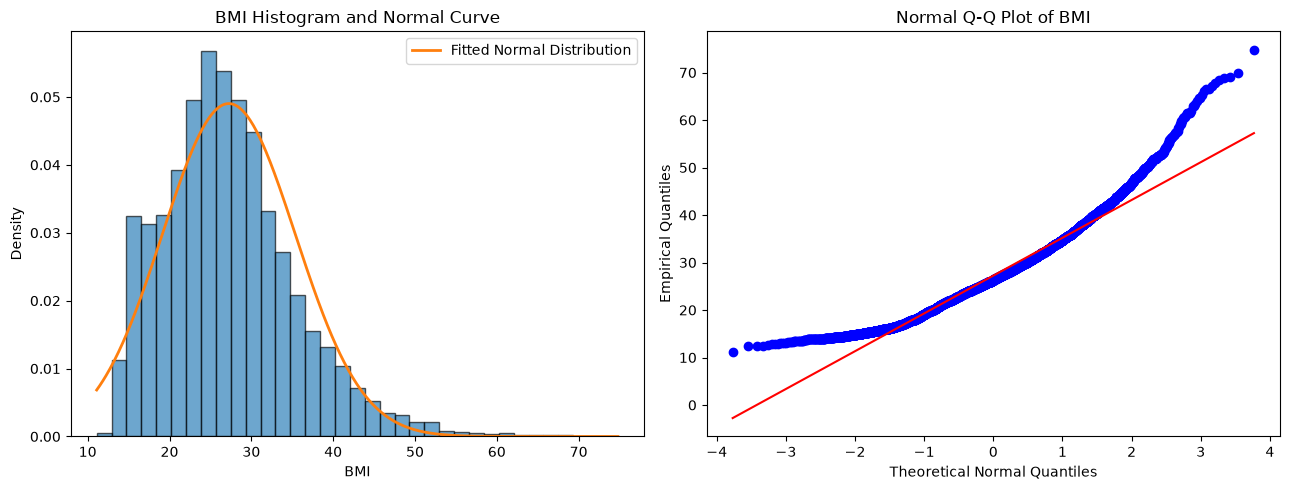

In [9]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# --------------------------------------------------
# 1. Load BMI data
# --------------------------------------------------

df = pd.read_csv("BMI_FINAL.csv")


bmi = df["BMXBMI"]


# Remove missing and non-finite observations
bmi = pd.to_numeric(bmi, errors="coerce").dropna()
bmi = bmi[np.isfinite(bmi)]

# --------------------------------------------------
# 2. Descriptive statistics
# --------------------------------------------------

print("Number of observations:", len(bmi))
print("Mean:", bmi.mean())
print("Median:", bmi.median())
print("Standard deviation:", bmi.std())
print("Skewness:", stats.skew(bmi))
print("Excess kurtosis:", stats.kurtosis(bmi))

# --------------------------------------------------
# 3. Create plots
# --------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Histogram and theoretical normal curve
axes[0].hist(
    bmi,
    bins=35,
    density=True,
    alpha=0.65,
    edgecolor="black"
)

# Normal distribution using sample mean and SD
x = np.linspace(bmi.min(), bmi.max(), 500)
normal_curve = stats.norm.pdf(
    x, loc=bmi.mean(), scale=bmi.std()
)

axes[0].plot(
    x,
    normal_curve,
    linewidth=2,
    label="Fitted Normal Distribution"
)

axes[0].set_title("BMI Histogram and Normal Curve")
axes[0].set_xlabel("BMI")
axes[0].set_ylabel("Density")
axes[0].legend()

# Normal Q-Q plot
stats.probplot(
    bmi,
    dist="norm",
    plot=axes[1]
)

axes[1].set_title("Normal Q-Q Plot of BMI")
axes[1].set_xlabel("Theoretical Normal Quantiles")
axes[1].set_ylabel("Empirical Quantiles")

plt.tight_layout()

# Save the complete figure
plt.savefig(
    "BMI_Normality_Analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [11]:

import pandas as pd
import numpy as np

# =========================================================
# 1. Load dataset
# =========================================================

df = pd.read_csv("BMI_FINAL.csv")

# Required columns
required_columns = [
    "BMXBMI",
    "WTMEC2YR",
    "MET_Level",
    "Smoking_Level"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

# Convert numerical columns
df["BMXBMI"] = pd.to_numeric(df["BMXBMI"], errors="coerce")
df["WTMEC2YR"] = pd.to_numeric(df["WTMEC2YR"], errors="coerce")

# Keep valid BMI measurements and positive weights
df = df.dropna(subset=["BMXBMI", "WTMEC2YR"])
df = df[df["WTMEC2YR"] > 0].copy()

# =========================================================
# 2. Define BMI categories
# =========================================================

bmi_bins = [-np.inf, 18.5, 25, 30, 40, np.inf]

bmi_labels = [
    "Underweight",
    "Normal Weight",
    "Overweight",
    "Obese",
    "Severely Obese"
]

df["BMI_Category"] = pd.cut(
    df["BMXBMI"],
    bins=bmi_bins,
    labels=bmi_labels,
    right=False
)

# =========================================================
# 3. Weighted mean, variance and standard deviation
# =========================================================

def weighted_statistics(data, group_column):

    results = []

    for group, subset in data.groupby(group_column, observed=True):

        x = subset["BMXBMI"].to_numpy()
        w = subset["WTMEC2YR"].to_numpy()

        weighted_mean = np.sum(w * x) / np.sum(w)

        weighted_variance = (
            np.sum(w * (x - weighted_mean)**2) / np.sum(w)
        )

        weighted_sd = np.sqrt(weighted_variance)

        results.append({
            "Group": group,
            "N": len(subset),
            "Weighted Mean BMI": weighted_mean,
            "Weighted Variance": weighted_variance,
            "Weighted SD": weighted_sd
        })

    return pd.DataFrame(results)


# =========================================================
# 4. Weighted BMI category proportions
# =========================================================

def weighted_categories(data, group_column):

    results = []

    for group, subset in data.groupby(group_column, observed=True):

        total_weight = subset["WTMEC2YR"].sum()

        for category in bmi_labels:

            category_data = subset[
                subset["BMI_Category"] == category
            ]

            proportion = (
                category_data["WTMEC2YR"].sum() / total_weight
            )

            results.append({
                "Group": group,
                "BMI Category": category,
                "Weighted Proportion": proportion,
                "Percentage (%)": proportion * 100
            })

    return pd.DataFrame(results)


# =========================================================
# 5. Physical Activity Analysis
# =========================================================

PA_statistics = weighted_statistics(df, "MET_Level")

PA_categories = weighted_categories(df, "MET_Level")


# =========================================================
# 6. Smoking Status Analysis
# =========================================================

SS_statistics = weighted_statistics(df, "Smoking_Level")

SS_categories = weighted_categories(df, "Smoking_Level")


# =========================================================
# 7. Display results
# =========================================================

print("\n" + "="*65)
print("BMI STATISTICS BY PHYSICAL ACTIVITY")
print("="*65)

print(PA_statistics.round(3).to_string(index=False))

print("\n" + "="*65)
print("BMI CATEGORIES BY PHYSICAL ACTIVITY")
print("="*65)

print(PA_categories.round(4).to_string(index=False))


print("\n" + "="*65)
print("BMI STATISTICS BY SMOKING STATUS")
print("="*65)

print(SS_statistics.round(3).to_string(index=False))

print("\n" + "="*65)
print("BMI CATEGORIES BY SMOKING STATUS")
print("="*65)

print(SS_categories.round(4).to_string(index=False))






BMI STATISTICS BY PHYSICAL ACTIVITY
 Group    N  Weighted Mean BMI  Weighted Variance  Weighted SD
   0.0 1183             31.465             66.291        8.142
   1.0 1744             30.440             61.249        7.826
   2.0 1543             28.760             44.683        6.685
   3.0 1749             28.251             42.488        6.518

BMI CATEGORIES BY PHYSICAL ACTIVITY
 Group   BMI Category  Weighted Proportion  Percentage (%)
   0.0    Underweight               0.0133          1.3309
   0.0  Normal Weight               0.1935         19.3492
   0.0     Overweight               0.2904         29.0418
   0.0          Obese               0.3468         34.6756
   0.0 Severely Obese               0.1560         15.6025
   1.0    Underweight               0.0177          1.7706
   1.0  Normal Weight               0.2258         22.5765
   1.0     Overweight               0.3044         30.4412
   1.0          Obese               0.3366         33.6619
   1.0 Severely Obese


WEIGHTED PROPORTIONS
BMI Category   Underweight  Normal Weight  Overweight   Obese  Severely Obese
Inactive            0.0133         0.1935      0.2904  0.3468          0.1560
Low                 0.0177         0.2258      0.3044  0.3366          0.1155
Active              0.0177         0.2881      0.3472  0.2813          0.0657
Highly Active       0.0221         0.3322      0.3167  0.2706          0.0584

WEIGHTED PERCENTAGES (%)
BMI Category   Underweight  Normal Weight  Overweight  Obese  Severely Obese
Inactive              1.33          19.35       29.04  34.68           15.60
Low                   1.77          22.58       30.44  33.66           11.55
Active                1.77          28.81       34.72  28.13            6.57
Highly Active         2.21          33.22       31.67  27.06            5.84


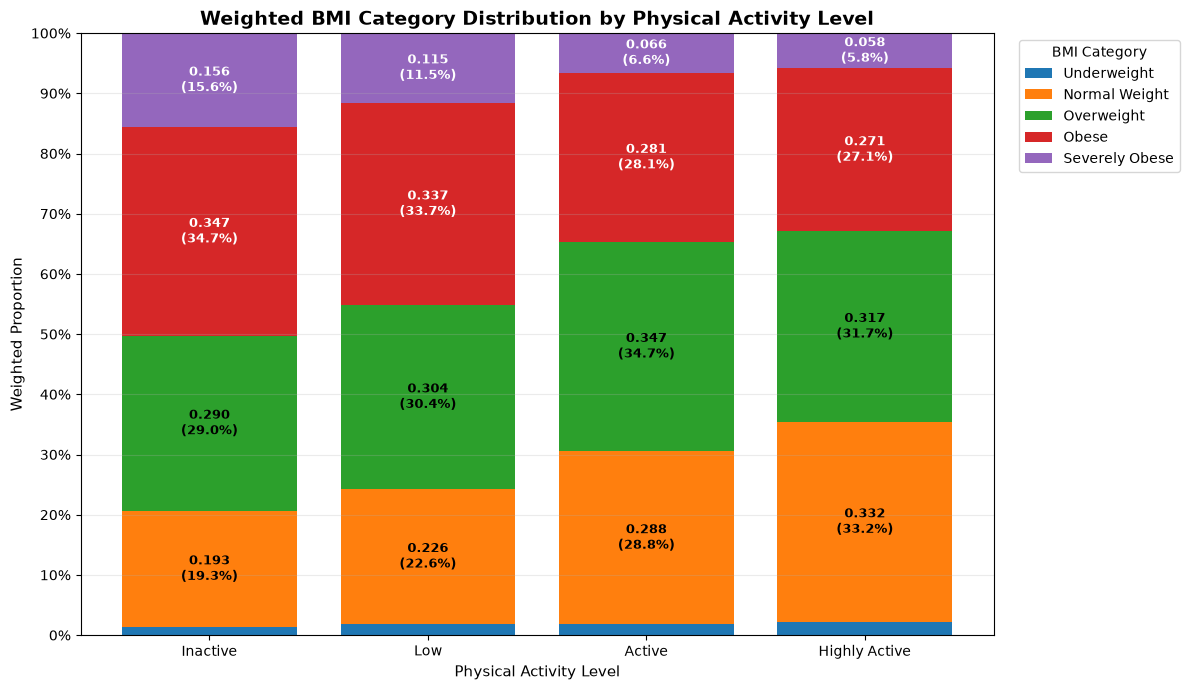

In [15]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# =========================================================
# 1. Prepare the data
# =========================================================

category_order = [
    "Underweight",
    "Normal Weight",
    "Overweight",
    "Obese",
    "Severely Obese"
]

group_names = {
    0.0: "Inactive",
    1.0: "Low",
    2.0: "Active",
    3.0: "Highly Active"
}

# Create a table of weighted proportions
proportion_table = PA_categories.pivot(
    index="Group",
    columns="BMI Category",
    values="Weighted Proportion"
)

# Create a table of percentages
percentage_table = PA_categories.pivot(
    index="Group",
    columns="BMI Category",
    values="Percentage (%)"
)

# Ensure correct order
proportion_table = proportion_table[category_order]
percentage_table = percentage_table[category_order]

# Sort groups and replace numerical codes with names
proportion_table = proportion_table.sort_index()
percentage_table = percentage_table.sort_index()

proportion_table.index = [
    group_names.get(x, str(x)) for x in proportion_table.index
]

percentage_table.index = [
    group_names.get(x, str(x)) for x in percentage_table.index
]

# =========================================================
# 2. Print numerical results
# =========================================================

print("\nWEIGHTED PROPORTIONS")
print(proportion_table.round(4))

print("\nWEIGHTED PERCENTAGES (%)")
print(percentage_table.round(2))

# =========================================================
# 3. Create stacked bar chart
# =========================================================

fig, ax = plt.subplots(figsize=(12, 7))

bottom = np.zeros(len(proportion_table))

for category in category_order:

    values = proportion_table[category].values

    bars = ax.bar(
        proportion_table.index,
        values,
        bottom=bottom,
        label=category
    )

    # Add proportion and percentage labels
    for i, value in enumerate(values):

        percentage = value * 100

        # Avoid overcrowding small segments
        if percentage >= 5:

            ax.text(
                i,
                bottom[i] + value / 2,
                f"{value:.3f}\n({percentage:.1f}%)",
                ha="center",
                va="center",
                fontsize=9,
                color="white" if category in [
                    "Obese", "Severely Obese"
                ] else "black",
                fontweight="bold"
            )

    bottom += values

# =========================================================
# 4. Format the figure
# =========================================================

ax.set_title(
    "Weighted BMI Category Distribution by Physical Activity Level",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Physical Activity Level", fontsize=11)
ax.set_ylabel("Weighted Proportion", fontsize=11)

ax.set_ylim(0, 1)
ax.set_yticks(np.arange(0, 1.1, 0.1))
ax.set_yticklabels([f"{x:.0%}" for x in np.arange(0, 1.1, 0.1)])

ax.legend(
    title="BMI Category",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(
    "Weighted BMI Category Distribution by Physical Activity Level.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


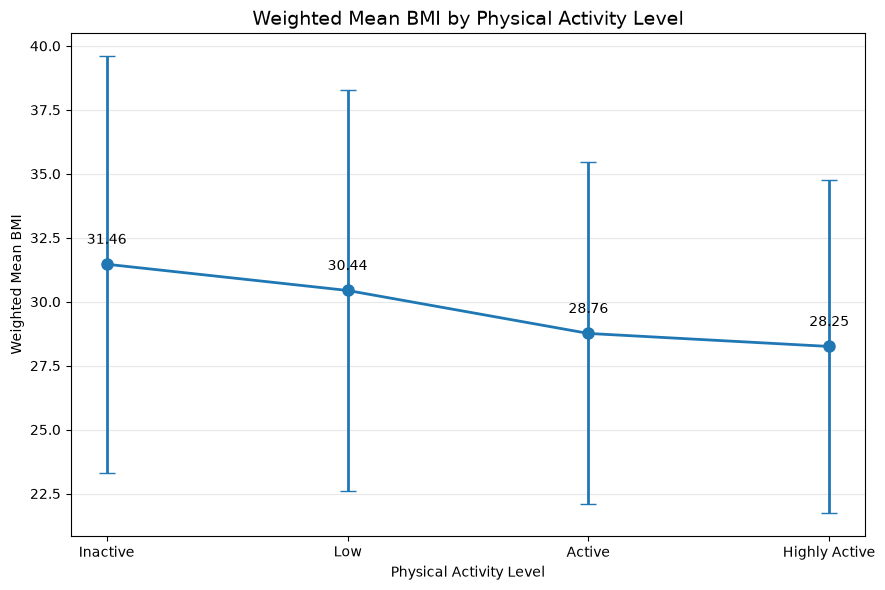

In [16]:

import matplotlib.pyplot as plt
import numpy as np

# Data
groups = ["Inactive", "Low", "Active", "Highly Active"]

means = [31.465, 30.440, 28.760, 28.251]
sd = [8.142, 7.826, 6.685, 6.518]

# Create figure
fig, ax = plt.subplots(figsize=(9, 6))

x = np.arange(len(groups))

ax.errorbar(
    x,
    means,
    yerr=sd,
    fmt="o-",
    capsize=6,
    markersize=8,
    linewidth=2
)

# Add mean labels
for i, mean in enumerate(means):
    ax.text(
        i,
        mean + 0.8,
        f"{mean:.2f}",
        ha="center",
        fontsize=10
    )

ax.set_xticks(x)
ax.set_xticklabels(groups)

ax.set_title(
    "Weighted Mean BMI by Physical Activity Level",
    fontsize=14
)

ax.set_xlabel("Physical Activity Level")
ax.set_ylabel("Weighted Mean BMI")

ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "Weighted Mean BMI by Physical Activity Level.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()



WEIGHTED PROPORTIONS
BMI Category  Underweight  Normal Weight  Overweight   Obese  Severely Obese
Never              0.0195         0.2904      0.3071  0.2858          0.0972
Former             0.0113         0.1985      0.3376  0.3506          0.1020
Current            0.0235         0.2810      0.3184  0.3174          0.0598

WEIGHTED PERCENTAGES (%)
BMI Category  Underweight  Normal Weight  Overweight  Obese  Severely Obese
Never                1.95          29.04       30.71  28.58            9.72
Former               1.13          19.85       33.76  35.06           10.20
Current              2.35          28.10       31.84  31.74            5.98


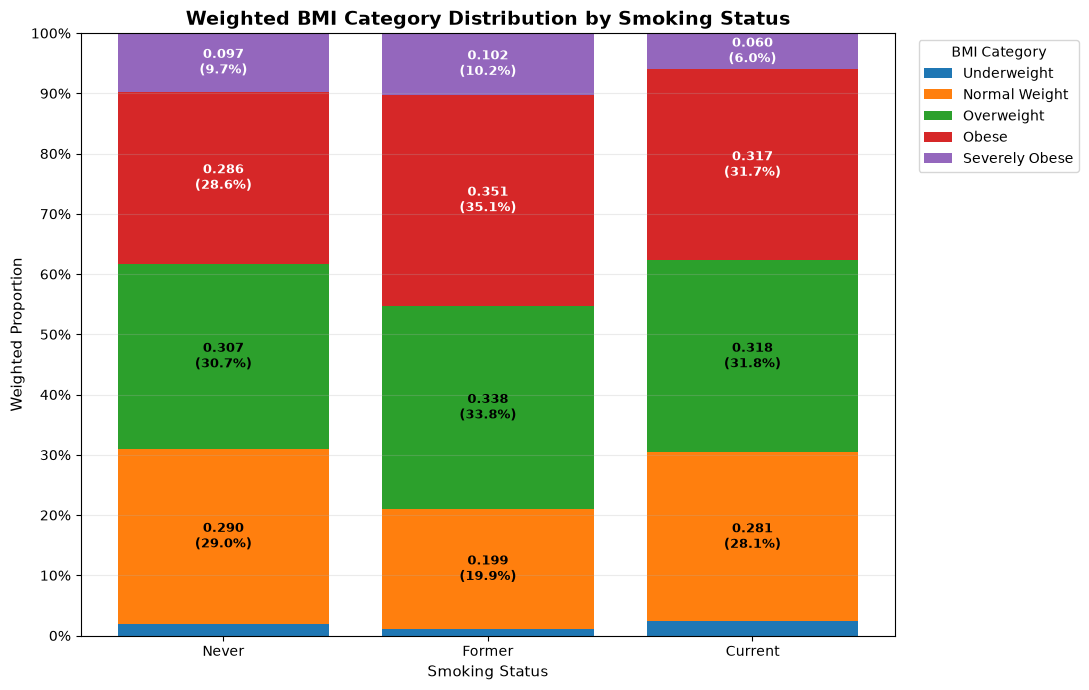

In [17]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# =========================================================
# 1. Prepare the data
# =========================================================

category_order = [
    "Underweight",
    "Normal Weight",
    "Overweight",
    "Obese",
    "Severely Obese"
]

group_names = {
    0.0: "Never",
    1.0: "Former",
    2.0: "Current"
}

# Create proportion table
proportion_table = SS_categories.pivot(
    index="Group",
    columns="BMI Category",
    values="Weighted Proportion"
)

# Create percentage table
percentage_table = SS_categories.pivot(
    index="Group",
    columns="BMI Category",
    values="Percentage (%)"
)

# Ensure correct order
proportion_table = proportion_table[category_order]
percentage_table = percentage_table[category_order]

# Sort groups
proportion_table = proportion_table.sort_index()
percentage_table = percentage_table.sort_index()

# Replace numerical codes with names
proportion_table.index = [
    group_names.get(x, str(x)) for x in proportion_table.index
]

percentage_table.index = [
    group_names.get(x, str(x)) for x in percentage_table.index
]

# =========================================================
# 2. Print numerical results
# =========================================================

print("\nWEIGHTED PROPORTIONS")
print(proportion_table.round(4))

print("\nWEIGHTED PERCENTAGES (%)")
print(percentage_table.round(2))

# =========================================================
# 3. Create stacked bar chart
# =========================================================

fig, ax = plt.subplots(figsize=(11, 7))

bottom = np.zeros(len(proportion_table))

for category in category_order:

    values = proportion_table[category].values

    ax.bar(
        proportion_table.index,
        values,
        bottom=bottom,
        label=category
    )

    # Add percentage labels
    for i, value in enumerate(values):

        percentage = value * 100

        if percentage >= 5:

            ax.text(
                i,
                bottom[i] + value / 2,
                f"{value:.3f}\n({percentage:.1f}%)",
                ha="center",
                va="center",
                fontsize=9,
                color="white" if category in [
                    "Obese", "Severely Obese"
                ] else "black",
                fontweight="bold"
            )

    bottom += values

# =========================================================
# 4. Format the figure
# =========================================================

ax.set_title(
    "Weighted BMI Category Distribution by Smoking Status",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Smoking Status", fontsize=11)
ax.set_ylabel("Weighted Proportion", fontsize=11)

ax.set_ylim(0, 1)
ax.set_yticks(np.arange(0, 1.1, 0.1))
ax.set_yticklabels([
    f"{x:.0%}" for x in np.arange(0, 1.1, 0.1)
])

ax.legend(
    title="BMI Category",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    "Weighted BMI Category Distribution by Smoking Status.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


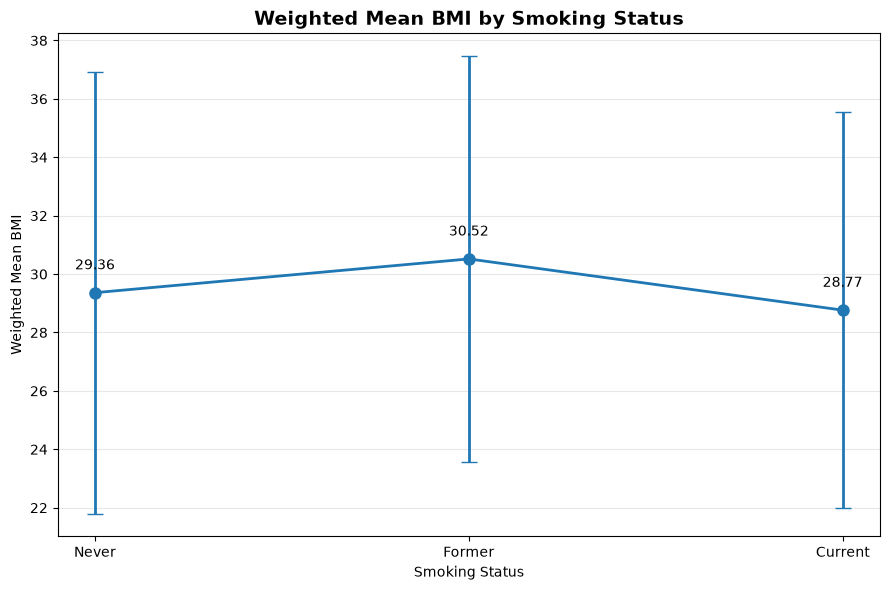

In [19]:

import matplotlib.pyplot as plt
import numpy as np

# =========================================================
# 1. Prepare data
# =========================================================

group_names = {
    0.0: "Never",
    1.0: "Former",
    2.0: "Current"
}

plot_data = SS_statistics.copy()

plot_data["Smoking Status"] = plot_data["Group"].map(group_names)

plot_data = plot_data.sort_values("Group")

groups = plot_data["Smoking Status"].tolist()

means = plot_data["Weighted Mean BMI"].to_numpy()
sd = plot_data["Weighted SD"].to_numpy()

# =========================================================
# 2. Create figure
# =========================================================

fig, ax = plt.subplots(figsize=(9, 6))

x = np.arange(len(groups))

ax.errorbar(
    x,
    means,
    yerr=sd,
    fmt="o-",
    capsize=6,
    markersize=8,
    linewidth=2
)

# Add mean labels
for i, mean in enumerate(means):

    ax.text(
        i,
        mean + 0.8,
        f"{mean:.2f}",
        ha="center",
        fontsize=10
    )

# =========================================================
# 3. Format figure
# =========================================================

ax.set_xticks(x)
ax.set_xticklabels(groups)

ax.set_title(
    "Weighted Mean BMI by Smoking Status",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Smoking Status")
ax.set_ylabel("Weighted Mean BMI")

ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "Weighted Mean BMI by Smoking Status.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


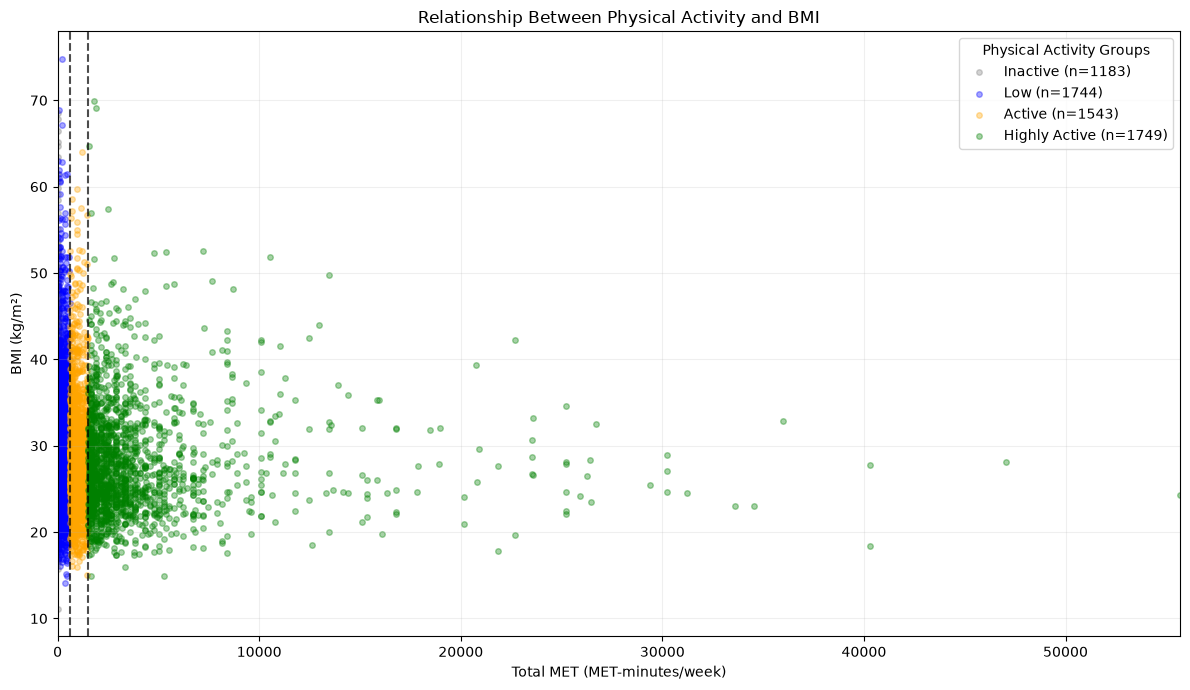

Total observations: 6219
MET_Level
0.0    1183
1.0    1744
2.0    1543
3.0    1749
Name: count, dtype: int64


In [9]:

import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv("BMI_FINAL.csv")

# Keep adults with valid BMI and physical activity
data = data[
    (data["RIDAGEYR"] >= 18) &
    (data["BMXBMI"] > 0) &
    (data["Total_MET"].notna()) &
    (data["MET_Level"].notna())
].copy()

# Numerical group codes
groups = {
    0: ("Inactive", "gray"),
    1: ("Low", "blue"),
    2: ("Active", "orange"),
    3: ("Highly Active", "green")
}

plt.figure(figsize=(12, 7))

for code, (name, color) in groups.items():

    subset = data[data["MET_Level"] == code]

    plt.scatter(
        subset["Total_MET"],
        subset["BMXBMI"],
        color=color,
        label=f"{name} (n={len(subset)})",
        alpha=0.35,
        s=16
    )

# Activity group boundaries
plt.axvline(600, color="black", linestyle="--", alpha=0.7)
plt.axvline(1500, color="black", linestyle="--", alpha=0.7)

plt.xlabel("Total MET (MET-minutes/week)")
plt.ylabel("BMI (kg/m²)")
plt.title("Relationship Between Physical Activity and BMI")

plt.legend(title="Physical Activity Groups")
plt.grid(alpha=0.2)

plt.xlim(0, data["Total_MET"].max())

plt.tight_layout()
plt.show()

print("Total observations:", len(data))
print(data["MET_Level"].value_counts().sort_index())


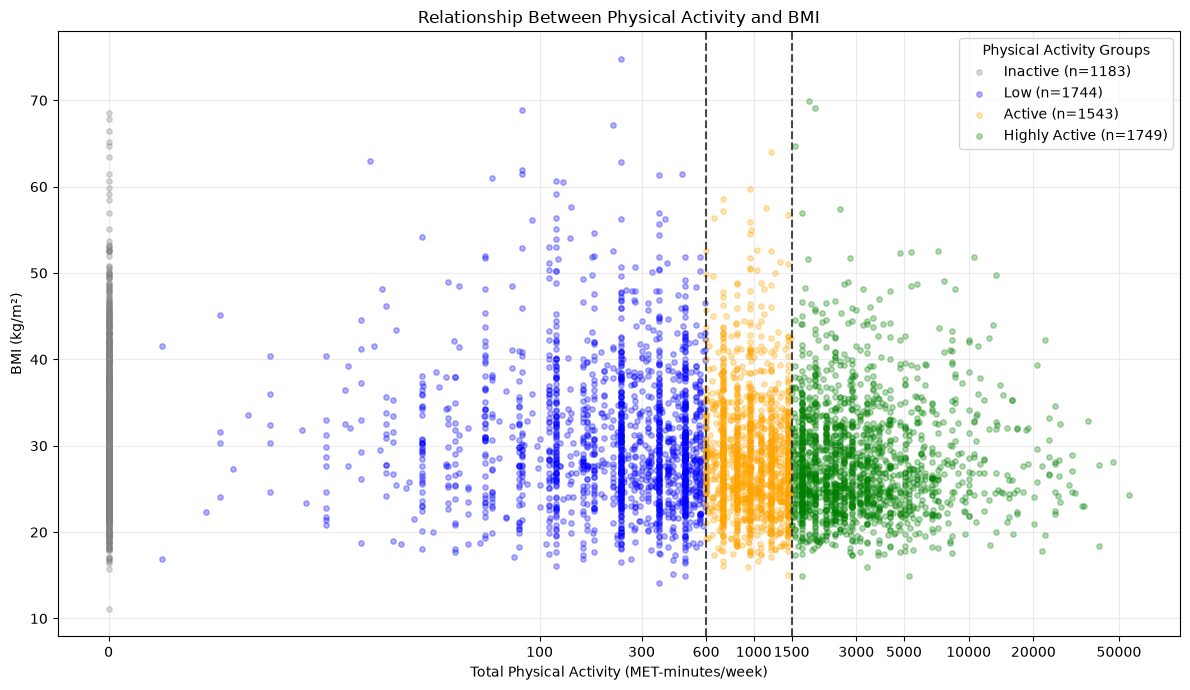

In [11]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data = pd.read_csv("BMI_FINAL.csv")

# Select valid observations
data = data[
    (data["RIDAGEYR"] >= 18) &
    (data["BMXBMI"] > 0) &
    (data["Total_MET"].notna()) &
    (data["MET_Level"].notna())
].copy()

# Logarithmic transformation
data["Log_MET"] = np.log10(1 + data["Total_MET"])

groups = {
    0: ("Inactive", "gray"),
    1: ("Low", "blue"),
    2: ("Active", "orange"),
    3: ("Highly Active", "green")
}

plt.figure(figsize=(12, 7))

for code, (name, color) in groups.items():

    subset = data[data["MET_Level"] == code]

    plt.scatter(
        subset["Log_MET"],
        subset["BMXBMI"],
        color=color,
        label=f"{name} (n={len(subset)})",
        alpha=0.3,
        s=15
    )

# Group boundaries in transformed coordinates
for boundary in [600, 1500]:
    plt.axvline(
        np.log10(1 + boundary),
        color="black",
        linestyle="--",
        alpha=0.7
    )

# Display original MET values as tick labels
ticks = [0, 100, 300, 600, 1000, 1500,
         3000, 5000, 10000, 20000, 50000]

plt.xticks(
    np.log10(1 + np.array(ticks)),
    ticks
)

plt.xlabel("Total Physical Activity (MET-minutes/week)")
plt.ylabel("BMI (kg/m²)")

plt.title("Relationship Between Physical Activity and BMI")

plt.legend(title="Physical Activity Groups")
plt.grid(alpha=0.25)

plt.tight_layout()
plt.savefig(
    "Relationship Between Physical Activity and BMI.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [12]:

import pandas as pd
import numpy as np

# Load dataset
data = pd.read_csv("BMI_FINAL.csv")

# Select complete observations
data = data[
    (data["RIDAGEYR"] >= 18) &
    (data["BMXBMI"] > 0) &
    (data["Total_MET"].notna()) &
    (data["Total_MET"] >= 0) &
    (data["WTMEC2YR"] > 0) &
    (data["WTMEC2YR"].notna())
].copy()

# Define variables
X = data["Total_MET"]
Y = data["BMXBMI"]
W = data["WTMEC2YR"]

# Logarithmic transformation
X_log = np.log10(1 + X)

# ------------------------------------------------
# 1. Ordinary sample covariance
# ------------------------------------------------

cov_ordinary = X.cov(Y)

# ------------------------------------------------
# 2. Survey-weighted covariance
# ------------------------------------------------

mean_X_w = np.average(X, weights=W)
mean_Y_w = np.average(Y, weights=W)

cov_weighted = np.sum(
    W * (X - mean_X_w) * (Y - mean_Y_w)
) / np.sum(W)

# ------------------------------------------------
# 3. Weighted covariance using log-transformed MET
# ------------------------------------------------

mean_Xlog_w = np.average(X_log, weights=W)

cov_log_weighted = np.sum(
    W * (X_log - mean_Xlog_w) * (Y - mean_Y_w)
) / np.sum(W)

# ------------------------------------------------
# Display results
# ------------------------------------------------

print("=" * 55)
print("COVARIANCE ANALYSIS: PHYSICAL ACTIVITY AND BMI")
print("=" * 55)

print("Number of observations:", len(data))

print("\n1. Ordinary Sample Covariance:")
print(cov_ordinary)

print("\n2. Survey-Weighted Covariance:")
print(cov_weighted)

print("\n3. Weighted Covariance (Log MET):")
print(cov_log_weighted)

print("\n" + "=" * 55)


COVARIANCE ANALYSIS: PHYSICAL ACTIVITY AND BMI
Number of observations: 6219

1. Ordinary Sample Covariance:
-2028.8940962568852

2. Survey-Weighted Covariance:
-1717.023531765817

3. Weighted Covariance (Log MET):
-1.3810522479567124



In [14]:

import pandas as pd
import numpy as np

# --------------------------------------------------
# 1. Load datasets
# --------------------------------------------------

sys = pd.read_csv("Systolic_Corrected_FINAL.csv")
dia = pd.read_csv("Diastolic_Corrected_FINAL.csv")

sys_col = "SYS_AVG"
dia_col = "DIA_AVG"

# --------------------------------------------------
# 2. Merge datasets using participant ID
# --------------------------------------------------

data = sys[
    ["SEQN", "RIAGENDR", "Smoking_Status", "RIDAGEYR", sys_col]
].merge(
    dia[["SEQN", dia_col]],
    on="SEQN",
    how="inner"
)

# Keep adults with complete observations
data = data[
    (data["RIDAGEYR"] >= 18) &
    data["RIAGENDR"].notna() &
    data["Smoking_Status"].notna() &
    data[sys_col].notna() &
    data[dia_col].notna()
].copy()

# --------------------------------------------------
# 3. Classify blood pressure
# --------------------------------------------------

def classify_bp(row):

    s = row[sys_col]
    d = row[dia_col]

    # Stage 2 has the highest priority
    if s >= 140 or d >= 90:
        return "Stage 2 Hypertension"

    # Stage 1
    elif s >= 130 or d >= 80:
        return "Stage 1 Hypertension"

    # Elevated
    elif 120 <= s <= 129 and d < 80:
        return "Elevated"

    # Normal
    else:
        return "Normal"


data["BP_Category"] = data.apply(classify_bp, axis=1)

# --------------------------------------------------
# 4. Gender labels
# --------------------------------------------------

data["Gender"] = data["RIAGENDR"].map({
    1: "Male",
    2: "Female"
})

data = data[data["Gender"].notna()].copy()

# --------------------------------------------------
# 5. Define the event: High BP
# --------------------------------------------------

# For this analysis, high BP includes Stage 1 and Stage 2.
data["High_BP"] = data["BP_Category"].isin([
    "Stage 1 Hypertension",
    "Stage 2 Hypertension"
])

print("Number of participants:", len(data))

print("\nBlood pressure category counts:")
print(data["BP_Category"].value_counts())

# --------------------------------------------------
# 6. P(High BP | Gender)
# --------------------------------------------------

print("\nP(High BP | Gender):")

gender_prob = data.groupby("Gender")["High_BP"].mean()
print(gender_prob)

# --------------------------------------------------
# 7. P(High BP | Smoking Status)
# --------------------------------------------------

print("\nP(High BP | Smoking Status):")

smoking_prob = data.groupby("Smoking_Status")["High_BP"].mean()
print(smoking_prob)

# --------------------------------------------------
# 8. P(High BP | Gender, Smoking Status)
# --------------------------------------------------

print("\nP(High BP | Gender, Smoking Status):")

joint_prob = data.groupby(
    ["Gender", "Smoking_Status"]
)["High_BP"].mean()

print(joint_prob)


# --------------------------------------------------
# 9. Bayes' theorem
# P(Male | High BP, Current Smoker)
# --------------------------------------------------

subset = data[data["Smoking_Status"] == "Current Smoker"]

# P(High BP | Male, Current Smoker)
p_high_given_male_current = subset.loc[
    subset["Gender"] == "Male", "High_BP"
].mean()

# P(Male | Current Smoker)
p_male_given_current = (
    subset["Gender"] == "Male"
).mean()

# P(High BP | Current Smoker)
p_high_given_current = subset["High_BP"].mean()

# Apply Bayes' theorem
if (
    len(subset) > 0
    and p_high_given_current > 0
    and not np.isnan(p_high_given_male_current)
):

    p_male_given_high_current = (
        p_high_given_male_current *
        p_male_given_current /
        p_high_given_current
    )

    print("\nBayes' theorem results:")

    print("P(High BP | Male, Current Smoker) =",
          p_high_given_male_current)

    print("P(Male | Current Smoker) =",
          p_male_given_current)

    print("P(High BP | Current Smoker) =",
          p_high_given_current)

    print("P(Male | High BP, Current Smoker) =",
          p_male_given_high_current)

else:
    print("Insufficient observations for this calculation.")

# --------------------------------------------------
# 10. Save results
# --------------------------------------------------

data.to_csv("Bayesian_BP_Analysis.csv", index=False)

print("\nFinal dataset saved.")


Number of participants: 6091

Blood pressure category counts:
BP_Category
Normal                  2819
Stage 1 Hypertension    1355
Stage 2 Hypertension    1092
Elevated                 825
Name: count, dtype: int64

P(High BP | Gender):
Gender
Female    0.379352
Male      0.428779
Name: High_BP, dtype: float64

P(High BP | Smoking Status):
Smoking_Status
Current Smoker    0.445578
Former Smoker     0.460841
Never Smoker      0.366266
Name: High_BP, dtype: float64

P(High BP | Gender, Smoking Status):
Gender  Smoking_Status
Female  Current Smoker    0.429668
        Former Smoker     0.452128
        Never Smoker      0.345363
Male    Current Smoker    0.458248
        Former Smoker     0.469105
        Never Smoker      0.397288
Name: High_BP, dtype: float64

Bayes' theorem results:
P(High BP | Male, Current Smoker) = 0.45824847250509165
P(Male | Current Smoker) = 0.5566893424036281
P(High BP | Current Smoker) = 0.445578231292517
P(Male | High BP, Current Smoker) = 0.5725190839694657


In [15]:

import pandas as pd
import numpy as np

# --------------------------------------------------
# 1. Load the dataset
# --------------------------------------------------

data = pd.read_csv("Triglycerides_FINAL.csv")

# --------------------------------------------------
# 2. Keep adults with valid measurements and weights
# --------------------------------------------------

data = data[
    (data["RIDAGEYR"] >= 18) &
    data["LBXTLG"].notna() &
    data["RIAGENDR"].notna() &
    data["WTSAF2YR"].notna() &
    (data["WTSAF2YR"] > 0)
].copy()

# --------------------------------------------------
# 3. Define the binary outcome
# --------------------------------------------------

data["Elevated_TG"] = (
    data["LBXTLG"] >= 150
).astype(int)

# --------------------------------------------------
# 4. Convert gender codes into labels
# --------------------------------------------------

data["Gender"] = data["RIAGENDR"].map({
    1: "Male",
    2: "Female"
})

data = data[data["Gender"].notna()].copy()

# --------------------------------------------------
# 5. Calculate probabilities by gender
# --------------------------------------------------

results = []

for gender, group in data.groupby("Gender"):

    # Unweighted sample size
    n = len(group)

    # Number of participants with elevated triglycerides
    cases = group["Elevated_TG"].sum()

    # Ordinary empirical probability
    unweighted_probability = group["Elevated_TG"].mean()

    # Survey-weighted probability
    weighted_probability = (
        (group["Elevated_TG"] * group["WTSAF2YR"]).sum()
        / group["WTSAF2YR"].sum()
    )

    results.append({
        "Gender": gender,
        "Sample Size": n,
        "Elevated TG Cases": cases,
        "Unweighted Probability": unweighted_probability,
        "Weighted Probability": weighted_probability,
        "Weighted Percentage": weighted_probability * 100
    })

results_df = pd.DataFrame(results)

print("\nTRIGLYCERIDES BY GENDER")
print("=" * 65)
print(results_df.to_string(index=False))

# --------------------------------------------------
# 6. Calculate the difference between genders
# --------------------------------------------------

probabilities = results_df.set_index("Gender")[
    "Weighted Probability"
]

difference = (
    probabilities["Male"] - probabilities["Female"]
)

print("\nDifference in weighted probabilities:")
print("Male - Female =", difference)

print("Difference in percentage points =",
      difference * 100)

# --------------------------------------------------
# 7. Save results
# --------------------------------------------------

results_df.to_csv(
    "Triglycerides_Gender_Weighted_Results.csv",
    index=False
)



TRIGLYCERIDES BY GENDER
Gender  Sample Size  Elevated TG Cases  Unweighted Probability  Weighted Probability  Weighted Percentage
Female         1750                341                0.194857              0.177665            17.766497
  Male         1439                350                0.243224              0.247446            24.744584

Difference in weighted probabilities:
Male - Female = 0.06978087321271015
Difference in percentage points = 6.978087321271015


In [16]:

import pandas as pd

data = pd.read_csv("Triglycerides_FINAL.csv")

# Keep valid adult observations
data = data[
    (data["RIDAGEYR"] >= 18) &
    data["LBXTLG"].notna() &
    data["RIAGENDR"].notna() &
    data["WTSAF2YR"].notna() &
    (data["WTSAF2YR"] > 0)
].copy()

# Define binary outcomes
data["Y"] = (data["LBXTLG"] >= 150).astype(int)

data["Gender"] = data["RIAGENDR"].map({
    1: "Male",
    2: "Female"
})

results = []

for gender, group in data.groupby("Gender"):

    weights = group["WTSAF2YR"]
    total_weight = weights.sum()

    p_y1 = (
        (group["Y"] * weights).sum() / total_weight
    )

    p_y0 = (
        ((1 - group["Y"]) * weights).sum() / total_weight
    )

    results.append({
        "Gender": gender,
        "P(Y=0)": p_y0,
        "P(Y=1)": p_y1,
        "P(Y=0) (%)": p_y0 * 100,
        "P(Y=1) (%)": p_y1 * 100
    })

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

results_df.to_csv(
    "Triglycerides_Both_Outcomes_By_Gender.csv",
    index=False
)


Gender   P(Y=0)   P(Y=1)  P(Y=0) (%)  P(Y=1) (%)
Female 0.822335 0.177665   82.233503   17.766497
  Male 0.752554 0.247446   75.255416   24.744584


Number of valid participants: 3329
Estimated event probability: 0.12886752778612195
Event count: 429

Number of subsamples: 33
Subsample size: 100
Observed counts: [11 13 11 15 10 17  9 17 12 14 16 13 12 17 12  9 10 10 14 14  7  8 16 19
 15 15 12 14 13 18 13 10 11]

---------- COMPARISON ----------
Observed mean: 12.93939393939394
Theoretical mean: 12.886752778612195
Observed variance: 8.723599632690544
Theoretical variance: 11.226068806841504


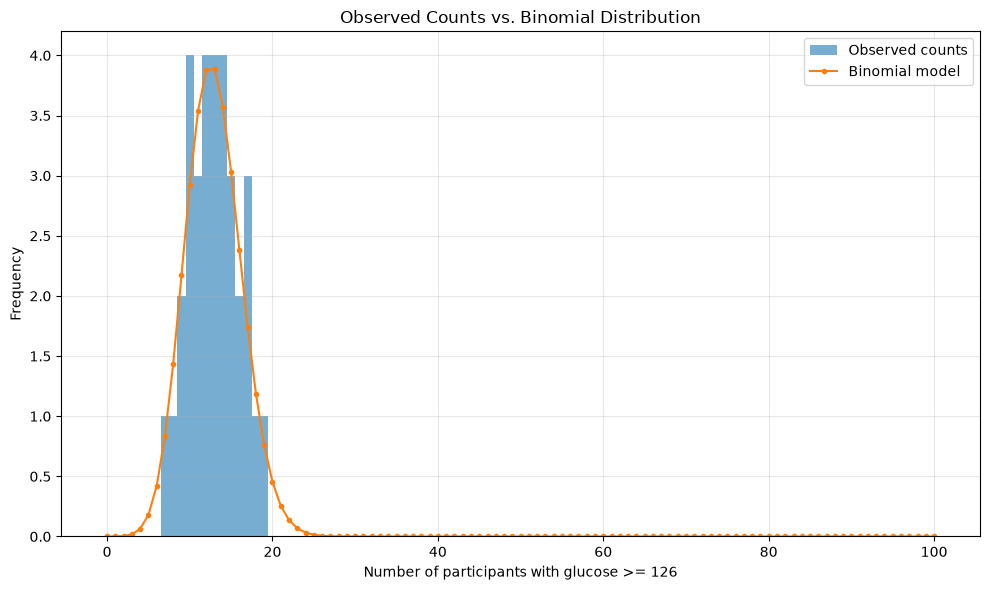

In [4]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binom

# -----------------------------------------
# Step 1: Load the dataset
# -----------------------------------------

df = pd.read_csv("Fasting_Glucose_FINAL.csv")

# Keep adults with valid glucose measurements
df = df.dropna(subset=["LBXGLU"])
df = df[df["LBXGLU"] >= 0]
df = df[df["RIDAGEYR"] >= 18]

print("Number of valid participants:", len(df))


# -----------------------------------------
# Step 2: Define the event
# -----------------------------------------

# Event = fasting glucose >= 126 mg/dL

df["Event"] = (df["LBXGLU"] >= 126).astype(int)

# Estimate the probability of the event
p = df["Event"].mean()

print("Estimated event probability:", p)
print("Event count:", df["Event"].sum())


# -----------------------------------------
# Step 3: Create equal-sized subsamples
# -----------------------------------------

n = 100  # Size of each subsample

N = len(df)

# Number of complete subsamples
B = N // n

# Randomly shuffle participants
rng = np.random.default_rng(42)

df = df.iloc[rng.permutation(N)].reset_index(drop=True)

# Count events in each subsample
counts = []

for j in range(B):

    start = j * n
    end = start + n

    subsample = df.iloc[start:end]

    event_count = subsample["Event"].sum()

    counts.append(event_count)

counts = np.array(counts)

print("\nNumber of subsamples:", B)
print("Subsample size:", n)
print("Observed counts:", counts)


# -----------------------------------------
# Step 4: Calculate binomial probabilities
# -----------------------------------------

k = np.arange(n + 1)

# Binomial probability mass function
binomial_probabilities = binom.pmf(k, n, p)

# Expected frequency for each count
expected_frequencies = B * binomial_probabilities


# -----------------------------------------
# Step 5: Compare observed and theoretical results
# -----------------------------------------

observed_mean = counts.mean()
theoretical_mean = n * p

observed_variance = counts.var()
theoretical_variance = n * p * (1 - p)

print("\n---------- COMPARISON ----------")

print("Observed mean:", observed_mean)
print("Theoretical mean:", theoretical_mean)

print("Observed variance:", observed_variance)
print("Theoretical variance:", theoretical_variance)


# -----------------------------------------
# Step 6: Plot the results
# -----------------------------------------

plt.figure(figsize=(10, 6))

# Observed frequencies
plt.hist(
    counts,
    bins=np.arange(-0.5, n + 1.5, 1),
    label="Observed counts",
    alpha=0.6
)

# Theoretical binomial frequencies
plt.plot(
    k,
    expected_frequencies,
    "o-",
    markersize=3,
    label="Binomial model"
)

plt.xlabel("Number of participants with glucose >= 126")
plt.ylabel("Frequency")

plt.title("Observed Counts vs. Binomial Distribution")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("Glucose_Binomial_Comparison.png", dpi=300)
plt.show()


Systolic observations: 7478
Diastolic observations: 7478

Systolic summary:
count    7478.000000
mean      119.097664
std        18.111297
min        71.333333
25%       106.333333
50%       116.333333
75%       129.000000
max       232.333333
Name: SYS_AVG, dtype: float64

Diastolic summary:
count    7478.000000
mean       72.222698
std        11.457914
min        34.000000
25%        64.000000
50%        71.666667
75%        79.333333
max       139.000000
Name: DIA_AVG, dtype: float64

Systolic BLOOD PRESSURE ANALYSIS
Sample size:          7478
Mean:                 119.0977
Median:               116.3333
Standard deviation:   18.1113
Variance:             328.0191
Skewness:             0.9886
Excess kurtosis:      1.8140

Outlier Analysis (1.5 × IQR):
Lower bound:          72.3333
Upper bound:          163.0000
Lower outliers:       1
Upper outliers:       175
Total outliers:       176
Outlier percentage:   2.35%

Normality Tests:
D'Agostino K² statistic: 1183.2415
D'Agostino p-valu

C:\Users\zaazi\AppData\Local\Temp\ipykernel_13844\2693348621.py:82: FutureWarning: As of SciPy 1.17, users must choose a p-value calculation method by providing the `method` parameter. `method='interpolate'` interpolates the p-value from pre-calculated tables; `method` may also be an instance of `MonteCarloMethod` to approximate the p-value via Monte Carlo simulation. When `method` is specified, the result object will include a `pvalue` attribute and not attributes `critical_value`, `significance_level`, or `fit_result`. Beginning in 1.19.0, these other attributes will no longer be available, and a p-value will always be computed according to one of the available `method` options.
  anderson_result = stats.anderson(data, dist="norm")
C:\Users\zaazi\AppData\Local\Temp\ipykernel_13844\2693348621.py:82: FutureWarning: As of SciPy 1.17, users must choose a p-value calculation method by providing the `method` parameter. `method='interpolate'` interpolates the p-value from pre-calculated tab

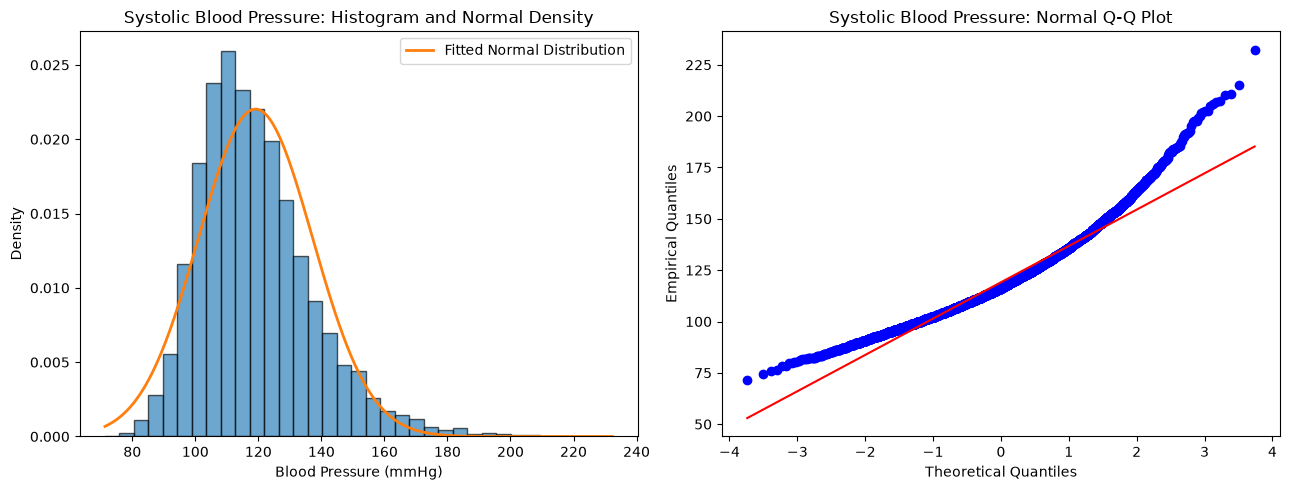

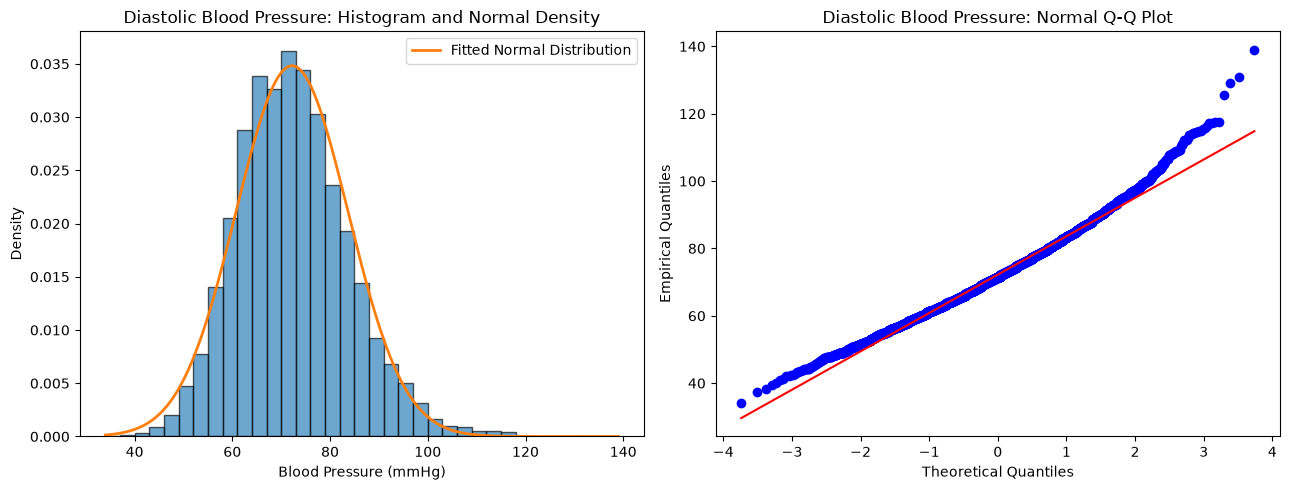

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy import stats


# --------------------------------------------------
# 1. Load the datasets
# --------------------------------------------------

systolic = pd.read_csv("Systolic_Corrected_FINAL.csv")
diastolic = pd.read_csv("Diastolic_Corrected_FINAL.csv")




# --------------------------------------------------
# 2. Select the blood pressure columns
# --------------------------------------------------

sbp = pd.to_numeric(
    systolic["SYS_AVG"], errors="coerce"
).dropna()

dbp = pd.to_numeric(
    diastolic["DIA_AVG"], errors="coerce"
).dropna()

print("Systolic observations:", len(sbp))
print("Diastolic observations:", len(dbp))

print("\nSystolic summary:")
print(sbp.describe())

print("\nDiastolic summary:")
print(dbp.describe())
# --------------------------------------------------
# 3. Statistical analysis
# --------------------------------------------------

def analyze_distribution(data, name):

    n = len(data)

    mean = data.mean()
    median = data.median()
    std = data.std()
    variance = data.var()

    skewness = stats.skew(data, bias=False)
    kurtosis = stats.kurtosis(data, bias=False)

    # Interquartile range and outliers
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data < lower_bound) | (data > upper_bound)
    ]

    lower_outliers = (data < lower_bound).sum()
    upper_outliers = (data > upper_bound).sum()

    # Normality tests
    dagostino_stat, dagostino_p = stats.normaltest(data)

    # Shapiro-Wilk: use a reproducible sample of at most 5000
    # observations because of its large-sample limitations.
    shapiro_sample = data.sample(
        n=min(n, 5000),
        random_state=42
    )

    shapiro_stat, shapiro_p = stats.shapiro(shapiro_sample)

    # Anderson-Darling test
    anderson_result = stats.anderson(data, dist="norm")

    print("\n" + "=" * 55)
    print(f"{name} BLOOD PRESSURE ANALYSIS")
    print("=" * 55)

    print(f"Sample size:          {n}")
    print(f"Mean:                 {mean:.4f}")
    print(f"Median:               {median:.4f}")
    print(f"Standard deviation:   {std:.4f}")
    print(f"Variance:             {variance:.4f}")

    print(f"Skewness:             {skewness:.4f}")
    print(f"Excess kurtosis:      {kurtosis:.4f}")

    print("\nOutlier Analysis (1.5 × IQR):")
    print(f"Lower bound:          {lower_bound:.4f}")
    print(f"Upper bound:          {upper_bound:.4f}")
    print(f"Lower outliers:       {lower_outliers}")
    print(f"Upper outliers:       {upper_outliers}")
    print(f"Total outliers:       {len(outliers)}")
    print(f"Outlier percentage:   {100*len(outliers)/n:.2f}%")

    print("\nNormality Tests:")

    print(f"D'Agostino K² statistic: {dagostino_stat:.4f}")
    print(f"D'Agostino p-value:      {dagostino_p:.6g}")

    print(f"Shapiro-Wilk statistic:  {shapiro_stat:.4f}")
    print(f"Shapiro-Wilk p-value:    {shapiro_p:.6g}")
    print(f"Shapiro sample size:     {len(shapiro_sample)}")

    print(f"Anderson-Darling statistic: {anderson_result.statistic:.4f}")
    print("Anderson-Darling critical values:")

    for significance, critical in zip(
        anderson_result.significance_level,
        anderson_result.critical_values
    ):
        print(f"{significance}% significance: {critical:.4f}")

    print("\nInterpretation:")
    if dagostino_p < 0.05:
        print("D'Agostino test rejects the normality hypothesis.")
    else:
        print("D'Agostino test does not reject the normality hypothesis.")

    if skewness > 0:
        print("The distribution is positively skewed.")
    elif skewness < 0:
        print("The distribution is negatively skewed.")
    else:
        print("The distribution is approximately symmetric.")

    return {
        "n": n,
        "mean": mean,
        "median": median,
        "std": std,
        "variance": variance,
        "skewness": skewness,
        "kurtosis": kurtosis,
        "outliers": len(outliers),
        "outlier_percentage": 100 * len(outliers) / n,
        "dagostino_p": dagostino_p,
        "shapiro_p": shapiro_p,
        "anderson_stat": anderson_result.statistic
    }


# --------------------------------------------------
# 4. Visual examination of normality
# --------------------------------------------------

def plot_normality(data, name, filename):

    mean = data.mean()
    std = data.std()

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # Histogram with fitted normal density
    axes[0].hist(
        data,
        bins=35,
        density=True,
        alpha=0.65,
        edgecolor="black"
    )

    x = np.linspace(data.min(), data.max(), 500)

    normal_density = stats.norm.pdf(x, mean, std)

    axes[0].plot(
        x,
        normal_density,
        linewidth=2,
        label="Fitted Normal Distribution"
    )

    axes[0].set_title(f"{name}: Histogram and Normal Density")
    axes[0].set_xlabel("Blood Pressure (mmHg)")
    axes[0].set_ylabel("Density")
    axes[0].legend()

    # Normal Q-Q plot
    stats.probplot(data, dist="norm", plot=axes[1])

    axes[1].set_title(f"{name}: Normal Q-Q Plot")
    axes[1].set_xlabel("Theoretical Quantiles")
    axes[1].set_ylabel("Empirical Quantiles")

    plt.tight_layout()

    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()


# --------------------------------------------------
# 5. Run analyses for both variables
# --------------------------------------------------

sbp_results = analyze_distribution(sbp, "Systolic")
dbp_results = analyze_distribution(dbp, "Diastolic")

plot_normality(
    sbp,
    "Systolic Blood Pressure",
    "Systolic_Normality_Analysis.png"
)

plot_normality(
    dbp,
    "Diastolic Blood Pressure",
    "Diastolic_Normality_Analysis.png"
)


Number of eligible participants: 3329

Event count: 429
Unweighted probability: 0.12886752778612195
Weighted probability: 0.10691082714959947
Unweighted percentage: 12.886752778612195
Weighted percentage: 10.691082714959947

Number of subsamples: 33
Subsample size: 100
Observed counts: [11 13 11 15 10 17  9 17 12 14 16 13 12 17 12  9 10 10 14 14  7  8 16 19
 15 15 12 14 13 18 13 10 11]

---------- COMPARISON ----------
Observed mean: 12.93939393939394
Observed variance: 8.723599632690544

Unweighted theoretical mean: 12.886752778612195
Unweighted theoretical variance: 11.226068806841504

Weighted theoretical mean: 10.691082714959947
Weighted theoretical variance: 9.548090218778794


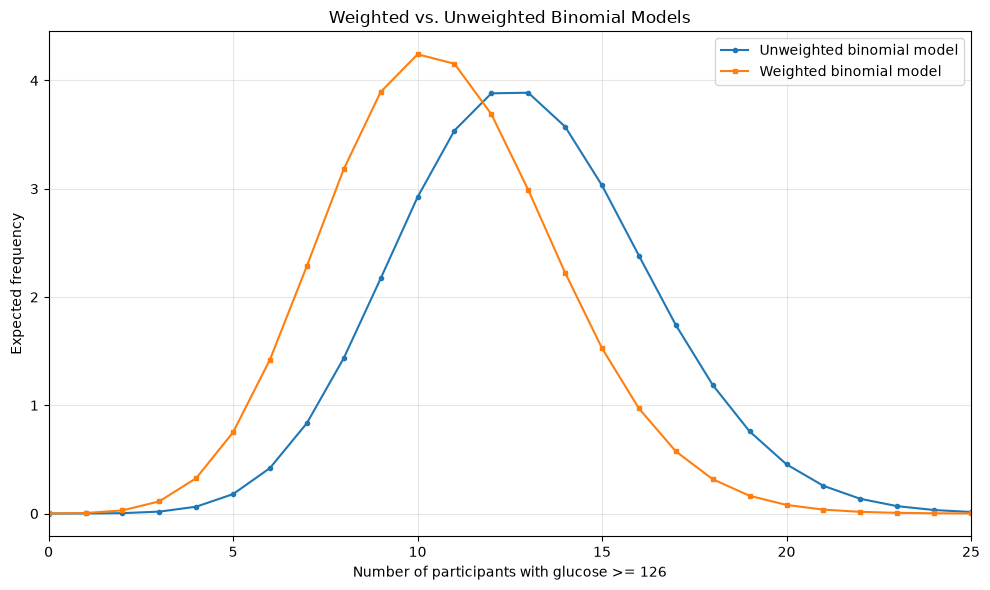

In [7]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binom

# -----------------------------------------
# Step 1: Load and prepare the dataset
# -----------------------------------------

df = pd.read_csv("Fasting_Glucose_FINAL.csv")

# Keep adults with valid glucose measurements
# and positive fasting subsample weights
df = df.dropna(subset=["LBXGLU", "WTSAF2YR", "RIDAGEYR"])
df = df[
    (df["RIDAGEYR"] >= 18) &
    (df["LBXGLU"] >= 0) &
    (df["WTSAF2YR"] > 0)
].copy()

print("Number of eligible participants:", len(df))


# -----------------------------------------
# Step 2: Define the event
# -----------------------------------------

# Event = fasting glucose >= 126 mg/dL
df["Event"] = (df["LBXGLU"] >= 126).astype(int)

# Unweighted empirical probability
p_unweighted = df["Event"].mean()

# Weighted empirical probability
p_weighted = (
    (df["Event"] * df["WTSAF2YR"]).sum()
    / df["WTSAF2YR"].sum()
)

print("\nEvent count:", df["Event"].sum())
print("Unweighted probability:", p_unweighted)
print("Weighted probability:", p_weighted)

print("Unweighted percentage:", p_unweighted * 100)
print("Weighted percentage:", p_weighted * 100)


# -----------------------------------------
# Step 3: Create equal-sized subsamples
# -----------------------------------------

n = 100
N = len(df)
B = N // n

rng = np.random.default_rng(42)
df = df.iloc[rng.permutation(N)].reset_index(drop=True)

counts = []

for j in range(B):
    start = j * n
    end = start + n

    subsample = df.iloc[start:end]

    event_count = subsample["Event"].sum()
    counts.append(event_count)

counts = np.array(counts)

print("\nNumber of subsamples:", B)
print("Subsample size:", n)
print("Observed counts:", counts)


# -----------------------------------------
# Step 4: Compare theoretical models
# -----------------------------------------

k = np.arange(n + 1)

# Expected frequencies under the unweighted model
expected_unweighted = B * binom.pmf(k, n, p_unweighted)

# Expected frequencies under the weighted model
expected_weighted = B * binom.pmf(k, n, p_weighted)

# Observed statistics
observed_mean = counts.mean()
observed_variance = counts.var()

# Theoretical statistics: unweighted model
mean_unweighted = n * p_unweighted
var_unweighted = n * p_unweighted * (1 - p_unweighted)

# Theoretical statistics: weighted model
mean_weighted = n * p_weighted
var_weighted = n * p_weighted * (1 - p_weighted)

print("\n---------- COMPARISON ----------")

print("Observed mean:", observed_mean)
print("Observed variance:", observed_variance)

print("\nUnweighted theoretical mean:", mean_unweighted)
print("Unweighted theoretical variance:", var_unweighted)

print("\nWeighted theoretical mean:", mean_weighted)
print("Weighted theoretical variance:", var_weighted)


# -----------------------------------------
# Step 5: Plot the comparison
# -----------------------------------------


plt.figure(figsize=(10, 6))

plt.plot(
    k,
    expected_unweighted,
    "o-",
    markersize=3,
    label="Unweighted binomial model"
)

plt.plot(
    k,
    expected_weighted,
    "s-",
    markersize=3,
    label="Weighted binomial model"
)

plt.xlabel("Number of participants with glucose >= 126")
plt.ylabel("Expected frequency")
plt.title("Weighted vs. Unweighted Binomial Models")

plt.xlim(0, 25)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("Glucose_Weighted_Binomial_Comparison.png", dpi=300)
plt.show()
